# 02 — Génération de la base, prétraitement et caractéristiques

Le notebook 01 a montré que les bases prêtes à l'emploi ne contiennent que **15 séismes** : il faut en **générer**.
Ce notebook :
1. vérifie que notre générateur reproduit **exactement** les données des auteurs ;
2. génère **6 000 séismes synthétiques** avec du **bruit réel** ;
3. transforme chaque séisme (273 signaux) en **une ligne de caractéristiques** exploitable par XGBoost ;
4. sauvegarde le dataset (`data_processed/`) sans **jamais regarder le jeu de test** pour faire des choix.

| Choix (validé) | Valeur | Justification |
|---|---|---|
| Nombre de séismes | 6 000 (4 800 train / 1 200 test) | ≫ 1 000 lignes exigées, temps de calcul ~1 min |
| Magnitude | uniforme entre Mw 7,0 et 9,5 | pas de biais vers une magnitude ; modèle de source valable au-dessus de Mw 7 |
| Types de faille | chevauchement / normal / décrochement, 1/3 chacun | l'amplitude dépend du mécanisme (notebook 01) |
| Position | 15 sources de la grille fournie | seules positions pour lesquelles les noyaux sont fournis |
| Bruit réel | 18 h pour le train, 6 h pour le test | un même extrait de bruit ne sert jamais aux deux |
| Instant de décision | T = 300 s après l'origine | fin de la fenêtre fournie |
| Cible | Mw finale | ce qui compte pour l'alerte tsunami |

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config as C, pegs_io as io, generate as G, features as F, dataset as D

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
pd.set_option("display.width", 160); pd.set_option("display.max_rows", 80)
C.FIG_DIR.mkdir(parents=True, exist_ok=True); C.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
MEC_COLORS = {"chevauchement": C.C_SIGNAL, "normal": C.C_NOISY, "decrochement": "#1baf7a"}

kernels = io.load_kernels(C.KERNEL_FILE)
noise = io.load_noise(C.NOISE_FILE)

## 1. Le générateur reproduit-il les données officielles ?

Formule (cf. `src/generate.py`) :
$\text{PEGS}(s,t) = 10^{-22}\,\Big[\sum_{i=1}^{6} m_i\, K_i(s,t)\Big] \ast \dot M_0(t)$,
avec $K_i$ les noyaux de Green fournis, $m_i$ le tenseur des moments (calculé à partir de l'azimut, du pendage et
du glissement) et $\dot M_0$ le taux de moment. Test : on reconstruit les 15 séismes du fichier `03_PEGS_db` à partir
de leurs seuls paramètres.

In [2]:
pegs_ref, tp_ref, meta_ref, momrate_ref, mt_ref = io.load_pegs_db(C.PEGS_DB_FILE)
err_mt, err_pegs = [], []
for e in range(len(meta_ref)):
    mt = G.moment_tensor(*meta_ref.loc[e, ["strike", "dip", "rake"]])
    err_mt.append(np.abs(mt - mt_ref[e]).max())
    k = np.where((kernels["srclat"] == meta_ref.srclat[e]) & (kernels["srclon"] == meta_ref.srclon[e]))[0][0]
    p = G.synth_pegs(kernels, k, mt, momrate_ref[e].astype(float))
    err_pegs.append(np.abs(p - pegs_ref[e]).max() / np.abs(pegs_ref[e]).max())
print(f"Tenseur des moments : écart max = {max(err_mt):.1e}")
print(f"PEGS reconstruits   : erreur relative max = {max(err_pegs):.1e}  (sur {len(meta_ref)} séismes)")

Tenseur des moments : écart max = 2.0e-07
PEGS reconstruits   : erreur relative max = 3.2e-07  (sur 15 séismes)


**Conclusion** : erreur relative ~10⁻⁷ (précision des nombres flottants) → notre générateur est **identique** à celui
des auteurs pour la partie physique. Ce que nous **ajoutons** (et qui relève de nos hypothèses) : le tirage aléatoire
des magnitudes, des mécanismes et de la fonction source.

## 2. La fonction source : comment l'énergie est libérée

Modèle de Meier et al. (2017), repris par Licciardi et al. (2022) : la durée de rupture augmente avec la magnitude,
avec une variabilité aléatoire et des irrégularités.

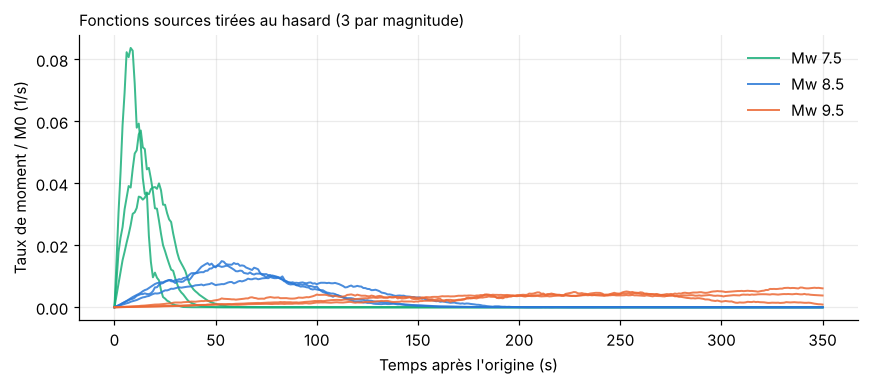

In [3]:
rng = np.random.default_rng(C.RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8, 3.6))
for mw, col in [(7.5, "#1baf7a"), (8.5, C.C_SIGNAL), (9.5, C.C_NOISY)]:
    for i in range(3):
        stf = G.source_time_function(rng, mw)
        ax.plot(stf / 10 ** (1.5 * mw + 9.1), color=col, lw=1.3, alpha=0.85, label=f"Mw {mw}" if i == 0 else None)
ax.set_xlabel("Temps après l'origine (s)"); ax.set_ylabel("Taux de moment / M0 (1/s)")
ax.set_title("Fonctions sources tirées au hasard (3 par magnitude)", loc="left", fontsize=10)
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(C.FIG_DIR / "02_fonctions_source.png"); plt.show()

**Lecture** : un Mw 7,5 libère son énergie en ~20 s, un Mw 9,5 en plusieurs minutes. Les courbes irrégulières
imitent les vraies ruptures. Comme dans la base des auteurs, la fonction source est **tronquée à 351 s** : pour les
plus gros séismes, une partie de l'énergie arrive donc encore après l'instant de décision (300 s).

## 3. À quoi ressemble un séisme généré, vu par tout le réseau ?

Même position, même mécanisme (chevauchement), **même bruit** : seule la magnitude change. Chaque ligne de l'image
est une station (triée par longitude), la couleur est l'accélération.

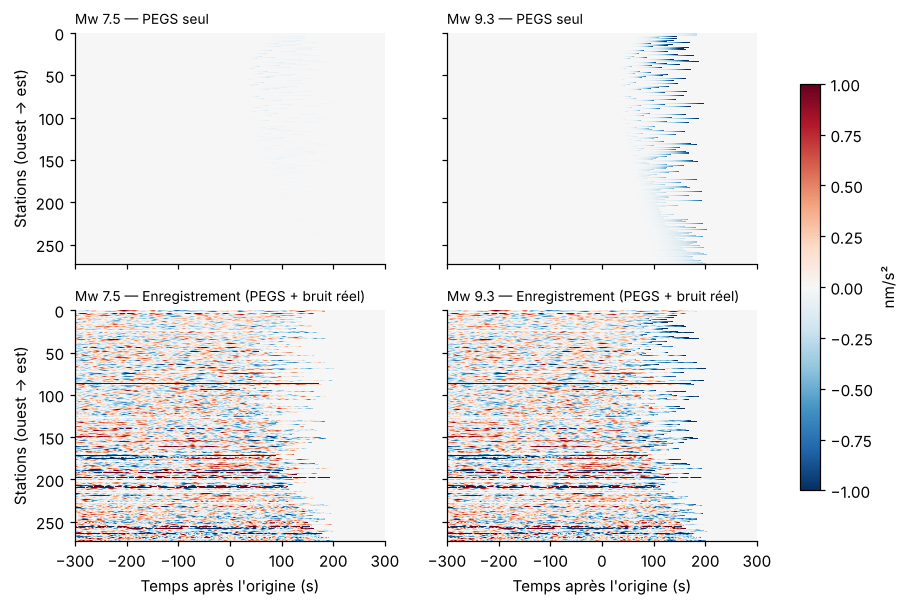

In [4]:
rng = np.random.default_rng(3)
k = 6                                                     # une source de la grille (57°N, 156°W)
mt = G.moment_tensor(240, 20, 90)                         # chevauchement pur
w, start = C.NOISE_TRAIN[0], 1000
order = np.argsort(io.load_stations(C.KERNEL_FILE).lon.values)
t = np.arange(G.N_WIN) - G.ORIGIN
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
for col, mw in enumerate([7.5, 9.3]):
    pegs = G.synth_pegs(kernels, k, mt, G.source_time_function(rng, mw))
    clean = np.zeros((pegs.shape[0], G.N_WIN)); clean[:, G.ORIGIN:] = pegs[:, :G.N_WIN - G.ORIGIN]
    rec = noise["noise"][w, :, start:start + G.N_WIN] + clean
    mask = t[None, :] > kernels["tp"][k][:, None]
    rec[mask] = 0; rec[~noise["flag"][w]] = 0
    for row, (img, lab) in enumerate([(clean, "PEGS seul"), (rec, "Enregistrement (PEGS + bruit réel)")]):
        ax = axes[row, col]
        im = ax.imshow(img[order] * 1e9, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1,
                       extent=[t[0], t[-1], len(order), 0], interpolation="none")
        ax.set_title(f"Mw {mw} — {lab}", fontsize=9, loc="left"); ax.grid(False)
for ax in axes[-1]: ax.set_xlabel("Temps après l'origine (s)")
for ax in axes[:, 0]: ax.set_ylabel("Stations (ouest → est)")
fig.colorbar(im, ax=axes, shrink=0.8, label="nm/s²")
fig.savefig(C.FIG_DIR / "02_seisme_reseau.png", bbox_inches="tight"); plt.show()

**Lecture** : pour Mw 9,3, le PEGS forme un motif cohérent sur de nombreuses stations (bandes de couleur juste avant
l'arrivée P, zone blanche à droite) et reste visible malgré le bruit. Pour Mw 7,5, le PEGS existe mais il est
**complètement noyé dans le bruit**. C'est la limite physique que le modèle va rencontrer.

## 4. Génération du dataset complet et extraction des caractéristiques

Chaque séisme (273 stations × 601 s) devient **une ligne** (cf. `src/features.py`) :

**Prétraitement** (station par station) :
1. écrêtage à ±10 nm/s² (comme Licciardi et al., 2022) pour neutraliser les pics de bruit aberrants ;
2. on ne garde que le signal entre l'origine et min(arrivée P, 300 s), et le bruit **avant** l'origine (connu) ;
3. on écarte les stations sans données, saturées (> 5 % d'échantillons écrêtés) ou avec < 10 s de signal.

Le bruit fourni est **déjà filtré** dans la bande 2–30 mHz (notebook 01) : pas de filtrage supplémentaire.

**Famille A — agrégats sur le réseau (61 colonnes)**

| Grandeur par station | Type | Sens physique |
|---|---|---|
| `log_rms`, `log_absmax` | temporelle | énergie / amplitude du signal avant l'onde P |
| `log_snr` | temporelle | rapport signal/bruit (bruit mesuré avant le séisme) |
| `end_snr` | temporelle | amplitude moyenne des 30 dernières s avant l'onde P (le PEGS y est maximal) / bruit |
| `slope_snr` | temporelle | pente sur les 60 dernières s / bruit (le PEGS est une « rampe ») |
| `log_e_*mHz` | spectrale | énergie dans 4 bandes : 1–5, 5–10, 10–20, 20–40 mHz |
| `log_bsnr_*mHz` | spectrale | énergie de la bande après / avant l'origine |

Puis pour chaque grandeur : **médiane, quantile 90 %, max, moyenne** sur les stations ; et le **nombre / la proportion
de stations** où le rapport signal/bruit dépasse 1,5, 2 et 3.

**Famille B — motif spatial (273 colonnes)** : pour chaque station, la valeur moyenne **signée** des 30 dernières
secondes avant l'onde P, divisée par le bruit. On décidera en validation croisée (notebook 03) si elle aide.

**Pourquoi pas de MFCC ?** L'échelle de Mel imite l'oreille humaine et est quasi **linéaire sous ~1 000 Hz**.
Nos signaux sont entre 2 et 30 **milli**hertz : les MFCC y deviendraient un simple cepstre linéaire, sans
information de plus que nos énergies par bande, et bien moins interprétables. Nous ne les utilisons donc pas.

In [5]:
t0 = time.time()
train = D.build_synthetic("train", kernels, noise)
test = D.build_synthetic("test", kernels, noise)
real = D.build_real()
print(f"Génération + caractéristiques : {time.time() - t0:.0f} s")
train.to_csv(C.PROCESSED_DIR / "train.csv", index=False)
test.to_csv(C.PROCESSED_DIR / "test.csv", index=False)
real.to_csv(C.PROCESSED_DIR / "real.csv", index=False)
feat_A = D.feature_columns(train, spatial=False)
feat_all = D.feature_columns(train, spatial=True)
print(f"train {train.shape}, test {test.shape}, réels {real.shape}")
print(f"Caractéristiques : famille A = {len(feat_A)}, famille B = {len(feat_all) - len(feat_A)}, total = {len(feat_all)}")

Génération + caractéristiques : 75 s


train (4800, 346), test (1200, 346), réels (4, 346)
Caractéristiques : famille A = 61, famille B = 273, total = 334


## 5. Contrôles du dataset

On vérifie : pas de séisme ni d'extrait de bruit commun entre train et test, équilibre des magnitudes et des
mécanismes, valeurs manquantes.

In [6]:
checks = pd.DataFrame({
    "train": [len(train), train.event_id.nunique(), sorted(train.noise_window.unique()).__len__(),
              round(train.mw.mean(), 2), round(train.mw.std(), 2),
              round(100 * train[feat_A].isna().mean().max(), 1), round(100 * train[feat_all].isna().mean().mean(), 1)],
    "test": [len(test), test.event_id.nunique(), sorted(test.noise_window.unique()).__len__(),
             round(test.mw.mean(), 2), round(test.mw.std(), 2),
             round(100 * test[feat_A].isna().mean().max(), 1), round(100 * test[feat_all].isna().mean().mean(), 1)]},
    index=["séismes", "identifiants uniques", "fenêtres de bruit (heures)", "Mw moyenne", "Mw écart-type",
           "% NaN max (famille A)", "% NaN moyen (A+B)"])
print("Séismes communs train/test :", len(set(train.event_id) & set(test.event_id)))
print("Fenêtres de bruit communes :", len(set(train.noise_window) & set(test.noise_window)))
display(checks)
both = pd.concat([train, test], ignore_index=True)
display(pd.crosstab(both.split, both.mecanisme))

Séismes communs train/test : 0
Fenêtres de bruit communes : 0


,train,test
séismes,4800.00,1200.00
identifiants uniques,4800.00,1200.00
fenêtres de bruit (heures),18.00,6.00
Mw moyenne,8.25,8.24
Mw écart-type,0.72,0.72
% NaN max (famille A),0.00,0.00
% NaN moyen (A+B),3.80,4.20


mecanisme,chevauchement,decrochement,normal
split,,,
test,400,400,400
train,1600,1600,1600


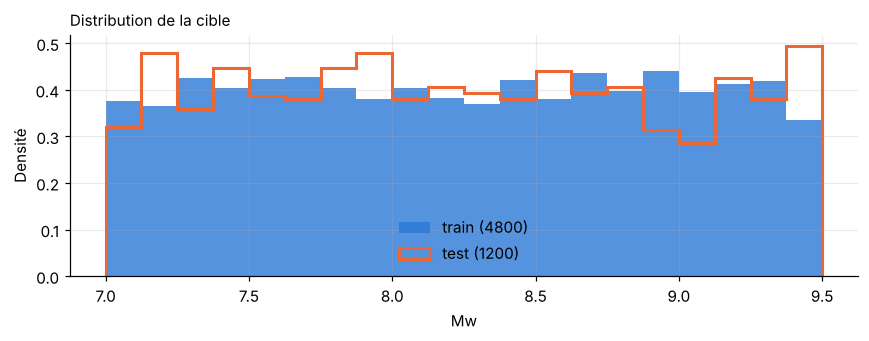

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.arange(7.0, 9.51, 0.125)
ax.hist(train.mw, bins=bins, color=C.C_SIGNAL, alpha=0.8, label=f"train ({len(train)})", density=True)
ax.hist(test.mw, bins=bins, histtype="step", color=C.C_NOISY, lw=2, label=f"test ({len(test)})", density=True)
ax.set_xlabel("Mw"); ax.set_ylabel("Densité"); ax.legend(frameon=False)
ax.set_title("Distribution de la cible", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "02_distribution_mw.png"); plt.show()

**Lecture** : distribution **uniforme** et identique en train et en test (voulu) ; aucun séisme ni aucune heure de bruit
en commun. Les NaN de la famille B correspondent aux stations sans données (~5 %) : XGBoost les gère nativement ;
pour Ridge, une **imputation par la médiane, ajustée sur le train uniquement**, sera placée dans le `Pipeline`.

**Rappel sur le regroupement** : une ligne = un séisme, donc un séisme ne peut pas être coupé en deux entre train et
test. Mais les séismes qui partagent la **même heure de bruit** se ressemblent : pour la validation croisée,
les groupes seront donc les **heures de bruit** (`noise_window`, 18 groupes dans le train) — plus strict qu'un simple
regroupement par séisme.

## 6. Relations caractéristiques ↔ magnitude (train uniquement)

,corrélation avec Mw (train)
n_snr_gt_1.5,0.639
frac_snr_gt_1.5,0.639
log_bsnr_1_5mHz__p90,0.601
log_bsnr_5_10mHz__p90,0.599
log_absmax__p90,0.594
log_snr__p90,0.589
log_absmax__med,0.579
log_bsnr_10_20mHz__p90,0.578
log_absmax__mean,0.576
log_e_10_20mHz__p90,0.576


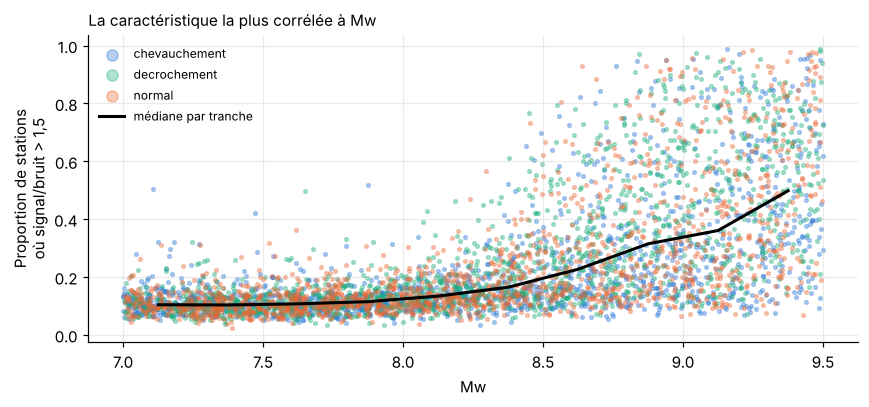

,médiane
mw,
"(7.0, 7.5]",0.104
"(7.5, 8.0]",0.111
"(8.0, 8.5]",0.146
"(8.5, 9.0]",0.268
"(9.0, 9.5]",0.435


In [8]:
corr = train[feat_A].corrwith(train.mw).sort_values(key=np.abs, ascending=False)
display(corr.head(10).round(3).to_frame("corrélation avec Mw (train)"))

x = "frac_snr_gt_1.5"
fig, ax = plt.subplots(figsize=(8, 3.8))
for m, g in train.groupby("mecanisme"):
    ax.scatter(g.mw, g[x], s=6, alpha=0.35, color=MEC_COLORS[m], label=m)
b = pd.cut(train.mw, np.arange(7, 9.51, 0.25))
med = train.groupby(b, observed=True)[x].median()
ax.plot([iv.mid for iv in med.index], med.values, color="k", lw=2, label="médiane par tranche")
ax.set_xlabel("Mw"); ax.set_ylabel("Proportion de stations\noù signal/bruit > 1,5")
ax.set_title("La caractéristique la plus corrélée à Mw", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, markerscale=3)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "02_feature_vs_mw.png"); plt.show()
train.groupby(pd.cut(train.mw, np.arange(7, 9.51, 0.5)), observed=True)[x].median().round(3).to_frame("médiane")

**Lecture** : jusqu'à Mw ≈ 8, la proportion de stations « au-dessus du bruit » reste au **niveau du hasard** (~10 %,
ce que donne du bruit pur) : le PEGS n'est pas détectable. Au-delà, elle augmente nettement (≈ 27 % entre 8,5 et 9,
≈ 44 % au-dessus de 9). On s'attend donc à :
- de **bonnes** estimations au-dessus de Mw ~8,3 ;
- des prédictions **ramenées vers la moyenne** en dessous de Mw ~8 (le modèle ne peut pas distinguer 7,2 de 7,8) ;
- une **dispersion** liée au mécanisme (les décrochements donnent ici plus de stations détectées).
Aucune caractéristique seule ne dépasse une corrélation de ~0,64 : c'est la combinaison qui devra faire le travail.

## 7. Les 4 séismes réels, comparés à la base synthétique

In [ ]:
cols = ["mw", "n_stations_ok", "median_log_noise", "frac_snr_gt_1.5", "log_snr__p90"]
cmp = real[["event_id"] + cols].copy()
ref = train[(train.mw - 7.8).abs() < 0.3]          # synthétiques de magnitude comparable
cmp.loc[len(cmp)] = ["synthétiques Mw 7,5-8,1 (médiane)"] + [ref[c].median() for c in cols]
cmp.round(3)

,event_id,mw,n_stations_ok,median_log_noise,frac_snr_gt_1.5,log_snr__p90
0,201801230931A_complete,7.925,238.0,-0.448,0.097,0.174
1,202007220612A_complete,7.804,244.0,-0.670,0.303,0.362
2,202010192054A_complete,7.560,248.0,-0.650,0.129,0.206
3,202107290615A_legacy,8.146,169.0,-0.308,0.130,0.220
4,"synthétiques Mw 7,5-8,1 (médiane)",7.789,261.0,-0.638,0.112,0.185


**Lecture** : le prétraitement donne des valeurs du même ordre en réel et en synthétique, avec deux écarts à retenir :
- **Kodiak 2018 et Chignik 2021 sont plus bruités** (bruit médian ≈ 0,36 et 0,49 nm/s², contre ≈ 0,23 pour les
  synthétiques) : le bruit des jours réels n'est pas celui des 24 h de bruit fournies ;
- **Shumagin 2020** a 30 % de stations « au-dessus du bruit », contre ~11 % pour un synthétique de même magnitude :
  écart réel/synthétique, ou autre signal présent dans la fenêtre — à surveiller.

Les 4 séismes sont **tous sous ou au seuil de détectabilité** (Mw 7,6 à 8,1) : il est honnête de s'attendre à des
estimations peu précises sur ces cas. Les auteurs eux-mêmes, avec un réseau de neurones sur graphe, ne stabilisent
ces magnitudes qu'après 70 à 150 s.

## 8. Bilan : le dataset prêt pour la modélisation

| Élément | Contenu |
|---|---|
| `data_processed/train.csv` | 4 800 séismes — servira à l'entraînement et à la validation croisée |
| `data_processed/test.csv` | 1 200 séismes — **utilisé une seule fois**, à la fin |
| `data_processed/real.csv` | 4 séismes réels — test final hors distribution |
| **X** | `D.feature_columns(df, spatial=False)` (famille A, 61 colonnes) ou `spatial=True` (+273) |
| **y** | `mw` |
| **groupes** | `noise_window` (heure de bruit réel) |
| Colonnes **interdites** au modèle | `META_COLS` : mécanisme, position, identifiants (servent à l'analyse des erreurs) |

**Limites à présenter** : données **synthétiques** (seul le bruit est réel) ; 15 positions de source seulement ;
24 h de bruit ; modèle de Terre 1D ; mécanismes tirés selon nos hypothèses ; arrivées P supposées connues exactement.